In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from tensorflow.keras.models import load_model
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, mean_squared_error

In [2]:
PROCESSED_DIR = Path("../dataset/processed")
MODELS_DIR = Path("../models")
RESULTS_DIR = Path("../results/comparison")

RESULTS_DIR.mkdir(parents=True, exist_ok=True)

In [3]:
X_test = np.load(PROCESSED_DIR / "X_test.npy")
y_test = np.load(PROCESSED_DIR / "y_test.npy")

X_test_lstm = X_test.reshape((X_test.shape[0], 1, X_test.shape[1]))

print("X_test:", X_test.shape)
print("X_test_lstm:", X_test_lstm.shape)
print("y_test:", y_test.shape)

X_test: (1326, 17)
X_test_lstm: (1326, 1, 17)
y_test: (1326,)


In [4]:
ann_model = load_model(MODELS_DIR / "ann_model_final.h5")
lstm_model = load_model(MODELS_DIR / "lstm_model_final.h5")

print("Models loaded successfully.")

Models loaded successfully.


In [5]:
ann_proba = ann_model.predict(X_test)
ann_pred = np.argmax(ann_proba, axis=1)

lstm_proba = lstm_model.predict(X_test_lstm)
lstm_pred = np.argmax(lstm_proba, axis=1)

42/42 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step
42/42 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step


In [6]:
def calculate_metrics(model_name, y_true, y_pred):
    return {
        "Model": model_name,
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision": precision_score(y_true, y_pred, average="weighted"),
        "Recall": recall_score(y_true, y_pred, average="weighted"),
        "F1-score": f1_score(y_true, y_pred, average="weighted"),
        "RMSE": np.sqrt(mean_squared_error(y_true, y_pred))
    }

In [7]:
comparison_df = pd.DataFrame([
    calculate_metrics("ANN", y_test, ann_pred),
    calculate_metrics("LSTM", y_test, lstm_pred)
])

comparison_df

,Model,Accuracy,Precision,Recall,F1-score,RMSE
0,ANN,0.874057,0.905307,0.874057,0.883558,0.354884
1,LSTM,0.877828,0.902472,0.877828,0.885232,0.349531


In [8]:
comparison_df.to_csv(RESULTS_DIR / "ann_lstm_comparison.csv", index=False)

print("Comparison saved.")

Comparison saved.


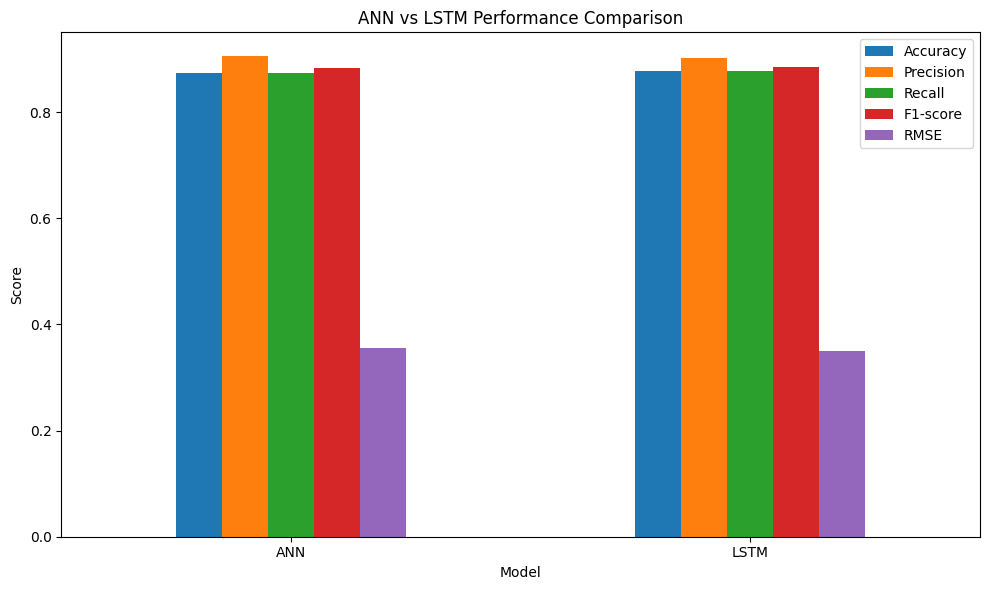

In [9]:
metrics = ["Accuracy", "Precision", "Recall", "F1-score", "RMSE"]

comparison_df.set_index("Model")[metrics].plot(kind="bar", figsize=(10, 6))

plt.title("ANN vs LSTM Performance Comparison")
plt.ylabel("Score")
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig(RESULTS_DIR / "ann_lstm_comparison_chart.png", dpi=300)
plt.show()

In [10]:
best_model = comparison_df.sort_values(
    by=["F1-score", "Accuracy"],
    ascending=False
).iloc[0]

print("Best model:")
print(best_model)

Best model:
Model            LSTM
Accuracy     0.877828
Precision    0.902472
Recall       0.877828
F1-score     0.885232
RMSE         0.349531
Name: 1, dtype: object


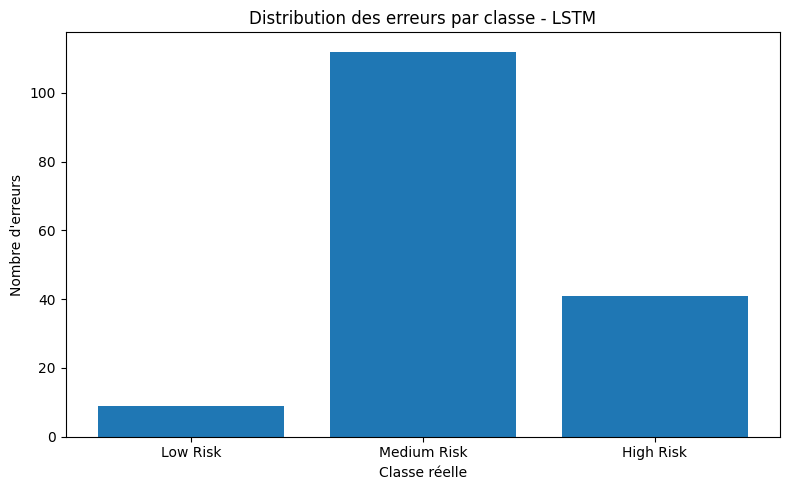

In [11]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix

classes = ["Low Risk", "Medium Risk", "High Risk"]

# Choose model predictions
# For ANN:
# y_pred = ann_pred

# For LSTM:
y_pred = lstm_pred

cm = confusion_matrix(y_test, y_pred)

errors_per_class = cm.sum(axis=1) - np.diag(cm)

plt.figure(figsize=(8, 5))
plt.bar(classes, errors_per_class)
plt.title("Distribution des erreurs par classe - LSTM")
plt.xlabel("Classe réelle")
plt.ylabel("Nombre d'erreurs")
plt.tight_layout()
plt.savefig("../results/lstm_error_distribution.png", dpi=300)
plt.show()

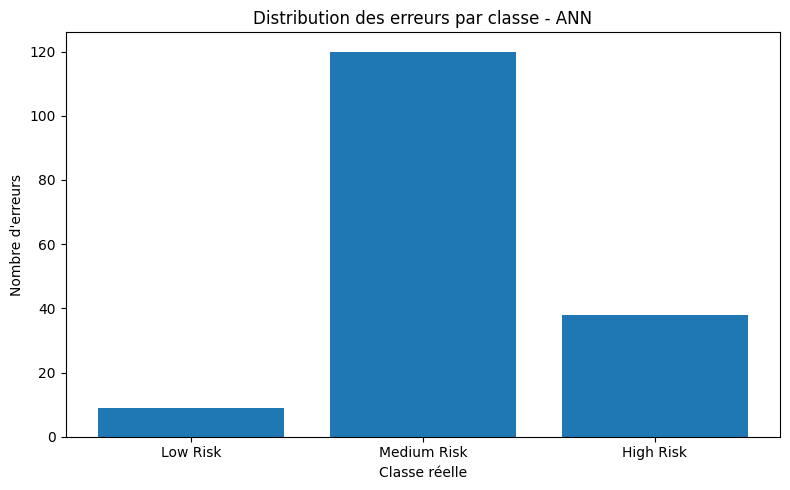

In [13]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix

classes = ["Low Risk", "Medium Risk", "High Risk"]

# Choose model predictions
# For ANN:
# y_pred = ann_pred

# For LSTM:
y_pred = ann_pred

cm = confusion_matrix(y_test, y_pred)

errors_per_class = cm.sum(axis=1) - np.diag(cm)

plt.figure(figsize=(8, 5))
plt.bar(classes, errors_per_class)
plt.title("Distribution des erreurs par classe - ANN")
plt.xlabel("Classe réelle")
plt.ylabel("Nombre d'erreurs")
plt.tight_layout()
plt.savefig("../results/ann_error_distribution.png", dpi=300)
plt.show()